# Student At-Risk Prediction — End-to-End Notebook

**Goal:** early in the term (around week 5), flag students who are likely to **fail the final exam** (score below 40)
so that a mentor can reach out and help them in time.

**Expected result:** a classifier that is clearly better than a "nobody is at risk" baseline, a probability threshold
chosen on purpose so that most struggling students are caught, an honest check of how it treats male and female
students, and the saved pipeline + `models/model_info.json` that the Flask API loads.

**Methods practised:** statistics (Module 04: summaries, chi-square test, t-test), exploratory data analysis
(Module 11) and classification (Module 08: pipelines, logistic regression, random forest, cross-validation,
confusion matrix, precision / recall / F1, ROC-AUC, thresholds).

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
jupyter notebook notebook/Student_Performance_Prediction.ipynb
```

The first code cell changes into the project root automatically if you started Jupyter inside `notebook/`.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())
RANDOM_STATE = 42
pd.set_option("display.width", 200)          # show wide tables without "..." in the middle
pd.set_option("display.max_columns", 20)

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/ML_Projects/02_Student_Performance_Prediction


## 1. Load the data and look at it

### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `student_id` | Row identifier (not a feature) | text |
| `gender` | Female / Male — used **only** for the fairness check, never as a feature | category |
| `age` | Age in years — not used as a feature (see section 4) | integer |
| `study_hours_per_week` | Self-reported self-study hours per week | number |
| `attendance_pct` | Attendance so far this term (%) | number |
| `previous_sem_gpa` | GPA of the previous semester (0–10 scale) | number |
| `assignments_submitted_pct` | Share of assignments submitted so far (%) | number |
| `internal_test_score` | Week-5 internal test, out of 50 | number |
| `part_time_job` | Works part-time | Yes / No |
| `commute_minutes` | One-way travel time to college | number |
| `family_support` | Support at home for studies | Low / Medium / High |
| `internet_access` | Reliable internet at home | Yes / No |
| `extracurricular` | Takes part in clubs / sports | Yes / No |
| `sleep_hours` | Average sleep per night | number |
| `final_score` | Final exam score (0–100), known only at the **end** of term | number |

**Target:** `at_risk = 1` if `final_score < 40` (fail), else `0`.

The data is synthetic (generated by `data/generate_data.py` with a fixed seed) but follows realistic patterns.

In [2]:
df = pd.read_csv("data/student_performance.csv")
print("Shape:", df.shape)
df.head()

Shape: (2030, 15)


,student_id,gender,age,study_hours_per_week,attendance_pct,previous_sem_gpa,assignments_submitted_pct,internal_test_score,part_time_job,commute_minutes,family_support,internet_access,extracurricular,sleep_hours,final_score
0,S01847,Male,19,8.7,86.9,6.57,85.0,27.0,No,31.0,Medium,Yes,No,5.0,53.0
1,S01472,Male,21,NaN,60.3,6.90,78.0,32.0,No,15.0,Medium,Yes,Yes,6.2,47.0
2,S01779,Female,21,0.0,67.1,5.19,48.0,23.0,No,25.0,High,No,No,6.8,43.0
3,S01412,Male,20,11.5,77.4,7.57,71.0,25.0,Yes,10.0,High,No,No,4.1,40.0
4,S00387,Male,19,7.1,73.8,6.48,86.0,26.0,Yes,30.0,Medium,Yes,No,8.3,49.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2030 entries, 0 to 2029
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 2030 non-null   str    
 1   gender                     2030 non-null   str    
 2   age                        2030 non-null   int64  
 3   study_hours_per_week       1985 non-null   float64
 4   attendance_pct             2000 non-null   float64
 5   previous_sem_gpa           2030 non-null   float64
 6   assignments_submitted_pct  2030 non-null   float64
 7   internal_test_score        2030 non-null   float64
 8   part_time_job              2030 non-null   str    
 9   commute_minutes            2005 non-null   float64
 10  family_support             1994 non-null   str    
 11  internet_access            2010 non-null   str    
 12  extracurricular            2030 non-null   str    
 13  sleep_hours                1990 non-null   float64
 14  fin

In [4]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nFully duplicated rows:", df.duplicated().sum())
print("Repeated student_id values:", df["student_id"].duplicated().sum())

Missing values per column:
study_hours_per_week    45
attendance_pct          30
commute_minutes         25
family_support          36
internet_access         20
sleep_hours             40
dtype: int64

Fully duplicated rows: 30
Repeated student_id values: 30


In [5]:
df.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
age,2030.0,19.9,1.5,18.0,19.0,20.0,21.0,24.0
study_hours_per_week,1985.0,11.5,8.2,-5.0,7.2,11.3,15.7,200.0
attendance_pct,2000.0,79.6,23.1,39.2,72.1,79.3,86.3,999.0
previous_sem_gpa,2030.0,6.6,1.4,3.0,5.7,6.7,7.5,10.0
assignments_submitted_pct,2030.0,80.5,12.7,39.0,72.0,81.0,90.0,100.0
internal_test_score,2030.0,26.9,6.5,7.0,23.0,27.0,31.0,50.0
commute_minutes,2005.0,30.4,19.9,5.0,16.0,26.0,41.0,120.0
sleep_hours,1990.0,6.9,1.2,-1.0,6.2,6.8,7.5,30.0
final_score,2030.0,50.7,13.2,3.0,41.0,51.0,60.0,94.0


**What to notice in `describe()`:** the maximum `attendance_pct` is far above 100, `sleep_hours` goes up to 30 (and
below 0), and `study_hours_per_week` reaches 200 — more hours than a week has awake time. These are **impossible values**
(typing mistakes). We also see a few hundred missing values and duplicated rows.

## 2. Clean the data

1. **Duplicates** — the same student entered twice. We drop them **before** splitting, otherwise a student could appear in
   both the training and the test set.
2. **Impossible values** — we cannot know the true value, so we turn them into *missing* (`NaN`). The pipeline fills
   missing values later using the training data only.
3. **Missing values** — not filled here (see step 2). Filling with a median must be learned from training data only.

In [6]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows; {len(df)} students remain")

# valid range for each column (anything outside is a data-entry mistake)
VALID_RANGES = {"attendance_pct": (0, 100), "sleep_hours": (3, 14), "study_hours_per_week": (0, 80)}
for col, (low, high) in VALID_RANGES.items():
    bad = (df[col] < low) | (df[col] > high)
    print(f"{col}: {bad.sum()} impossible values -> set to NaN", sorted(df.loc[bad, col].tolist()))
    df.loc[bad, col] = np.nan

Removed 30 duplicate rows; 2000 students remain
attendance_pct: 6 impossible values -> set to NaN [101.5, 105.0, 110.0, 120.0, 150.0, 999.0]
sleep_hours: 4 impossible values -> set to NaN [-1.0, 0.0, 24.0, 30.0]
study_hours_per_week: 3 impossible values -> set to NaN [-5.0, 168.0, 200.0]


### Create the target — and why `final_score` must then be dropped

`at_risk` is made from `final_score`. But `final_score` is only known **after** the final exam. If we kept it as a
feature, the model would simply learn "score < 40 → at risk" and look perfect in the notebook, yet it would be useless
in week 5 when no final score exists. Using information that will not be available at prediction time is called
**data leakage**. The cell below shows how "too good to be true" a leaky model looks.

In [7]:
df["at_risk"] = (df["final_score"] < 40).astype(int)

# Demonstration of leakage: a tiny tree that only sees final_score
leaky = cross_validate(DecisionTreeClassifier(max_depth=1), df[["final_score"]], df["at_risk"], cv=5,
                       scoring="recall")
print("Recall of a model that 'cheats' with final_score:", leaky["test_score"].mean().round(3))

df = df.drop(columns=["final_score"])
print("final_score dropped. Columns now:", list(df.columns))

Recall of a model that 'cheats' with final_score: 1.0
final_score dropped. Columns now: ['student_id', 'gender', 'age', 'study_hours_per_week', 'attendance_pct', 'previous_sem_gpa', 'assignments_submitted_pct', 'internal_test_score', 'part_time_job', 'commute_minutes', 'family_support', 'internet_access', 'extracurricular', 'sleep_hours', 'at_risk']


In [8]:
counts = df["at_risk"].value_counts()
print(counts)
print(f"\nShare of students at risk: {df['at_risk'].mean():.1%}")

at_risk
0    1615
1     385
Name: count, dtype: int64

Share of students at risk: 19.2%


The classes are **imbalanced**: only about one student in five is at risk. This matters later — a model that says
"nobody is at risk" would already be about 80% accurate while helping no one.

## 3. Explore the data (EDA)

### 3.1 Distributions: at-risk vs not at-risk students

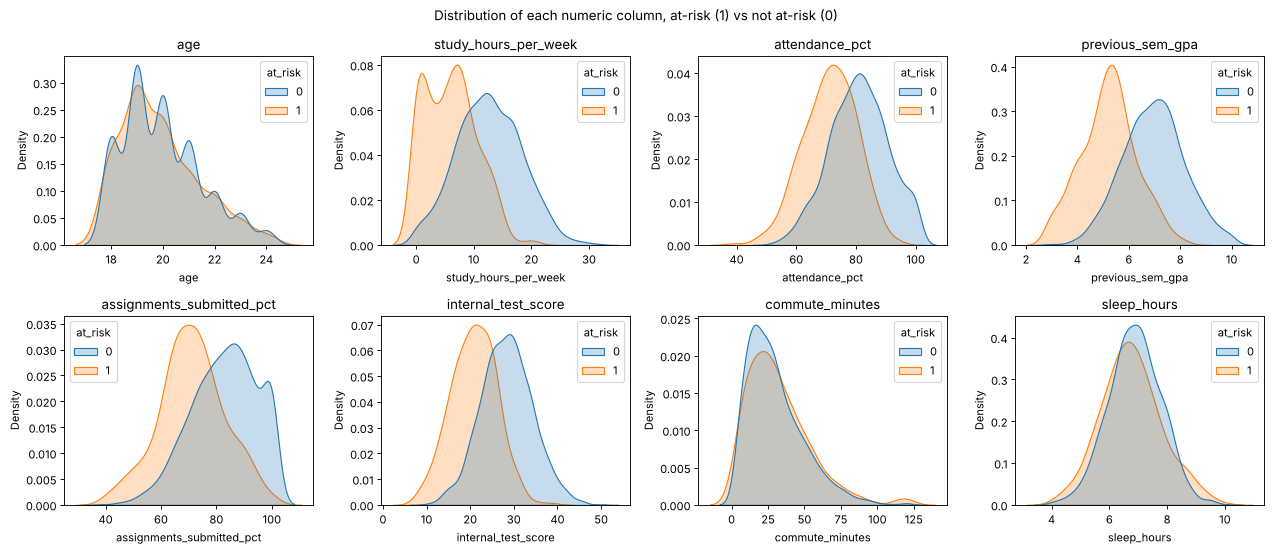

In [9]:
NUMERIC_ALL = ["age", "study_hours_per_week", "attendance_pct", "previous_sem_gpa", "assignments_submitted_pct",
               "internal_test_score", "commute_minutes", "sleep_hours"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUMERIC_ALL):
    sns.kdeplot(data=df, x=col, hue="at_risk", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.suptitle("Distribution of each numeric column, at-risk (1) vs not at-risk (0)")
plt.tight_layout()

In [10]:
df.groupby("at_risk")[NUMERIC_ALL].median().T.rename(columns={0: "median: not at risk", 1: "median: at risk"})

at_risk,median: not at risk,median: at risk
age,20.00,20.00
study_hours_per_week,12.50,5.95
attendance_pct,81.05,71.40
previous_sem_gpa,6.97,5.24
assignments_submitted_pct,84.00,71.00
internal_test_score,28.00,21.00
commute_minutes,26.00,27.00
sleep_hours,6.90,6.70


### 3.2 At-risk rate by group

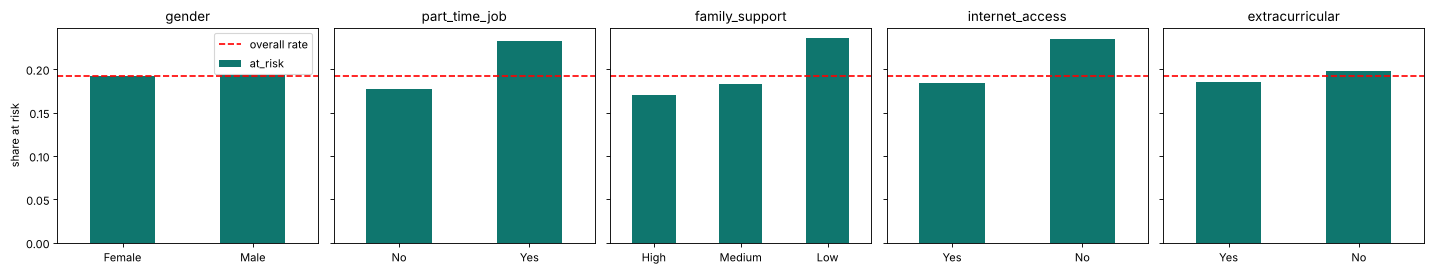

In [11]:
CATEGORICAL_ALL = ["gender", "part_time_job", "family_support", "internet_access", "extracurricular"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
overall = df["at_risk"].mean()
for ax, col in zip(axes, CATEGORICAL_ALL):
    rate = df.groupby(col)["at_risk"].mean().sort_values()
    rate.plot.bar(ax=ax, color="#0f766e")
    ax.axhline(overall, color="red", linestyle="--", label="overall rate")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("share at risk"); axes[0].legend()
plt.tight_layout()

In [12]:
for col in CATEGORICAL_ALL:
    print(df.groupby(col)["at_risk"].agg(students="size", at_risk_rate="mean").round(3), "\n")

        students  at_risk_rate
gender                        
Female       979         0.192
Male        1021         0.193 

               students  at_risk_rate
part_time_job                        
No                 1459         0.178
Yes                 541         0.233 

                students  at_risk_rate
family_support                        
High                 575         0.170
Low                  525         0.236
Medium               865         0.183 

                 students  at_risk_rate
internet_access                        
No                    341         0.235
Yes                  1639         0.184 

                 students  at_risk_rate
extracurricular                        
No                   1189         0.198
Yes                   811         0.185 



In [13]:
# At-risk rate by attendance band — a clear, explainable pattern
bands = pd.cut(df["attendance_pct"], bins=[0, 60, 70, 80, 90, 100])
df.groupby(bands, observed=True)["at_risk"].agg(students="size", at_risk_rate="mean").round(3)

,students,at_risk_rate
attendance_pct,,
"(0, 60]",73,0.630
"(60, 70]",295,0.403
"(70, 80]",679,0.227
"(80, 90]",632,0.090
"(90, 100]",285,0.014


### 3.3 Correlation

previous_sem_gpa            -0.506
internal_test_score         -0.458
study_hours_per_week        -0.436
attendance_pct              -0.374
assignments_submitted_pct   -0.367
sleep_hours                 -0.048
age                         -0.019
commute_minutes              0.045
dtype: float64


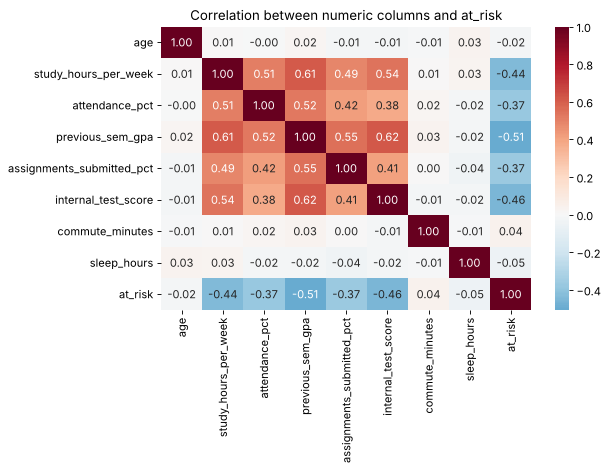

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[NUMERIC_ALL + ["at_risk"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation between numeric columns and at_risk")
plt.tight_layout()
print(df[NUMERIC_ALL].corrwith(df["at_risk"]).sort_values().round(3))

**What to notice:** at-risk students have a lower previous GPA, a lower internal test score, lower attendance, fewer
study hours and fewer assignments submitted. These habits are also correlated **with each other** (motivated students
do all of them), so no single column tells the whole story. `age`, `commute_minutes` and `sleep_hours` have only a
very weak *linear* correlation with `at_risk` (close to 0). Low family support, no internet and a part-time job go with
a higher at-risk rate (about 23–24% vs 19% overall), while the two gender groups have almost the same rate.

### 3.4 Back the insights with statistical tests (Module 04)

A difference in a chart could be luck. Two tests check that:

- **Chi-square test of independence** (category vs category): is having a part-time job related to being at risk?
  Null hypothesis H0: they are independent.
- **Welch t-test** (number vs two groups): do at-risk students have a different average attendance?
  H0: the two group means are equal.

If the **p-value is below 0.05** we reject H0 and call the difference statistically significant.

In [15]:
table = pd.crosstab(df["part_time_job"], df["at_risk"])
chi2, p_chi, dof, expected = stats.chi2_contingency(table)
print("Observed counts:\n", table)
print(f"\nChi-square = {chi2:.2f}, dof = {dof}, p-value = {p_chi:.2g}")

g_chi2, g_p, _, _ = stats.chi2_contingency(pd.crosstab(df["gender"], df["at_risk"]))
print(f"Same test for gender: chi-square = {g_chi2:.2f}, p-value = {g_p:.2g}")

att_risk = df.loc[df["at_risk"] == 1, "attendance_pct"].dropna()
att_ok = df.loc[df["at_risk"] == 0, "attendance_pct"].dropna()
t_stat, p_t = stats.ttest_ind(att_risk, att_ok, equal_var=False)
print(f"\nMean attendance: at risk {att_risk.mean():.1f}%, not at risk {att_ok.mean():.1f}%")
print(f"Welch t = {t_stat:.2f}, p-value = {p_t:.2g}")

Observed counts:
 at_risk           0    1
part_time_job           
No             1200  259
Yes             415  126

Chi-square = 7.44, dof = 1, p-value = 0.0064
Same test for gender: chi-square = 0.00, p-value = 1

Mean attendance: at risk 71.1%, not at risk 80.9%
Welch t = -18.77, p-value = 1.9e-62


**Reading the results:** the part-time job test gives a p-value below 0.05 (about 0.006) and the attendance t-test a
p-value that is practically zero, so both differences are very unlikely to be chance. The gender test gives a large p-value: we have **no evidence** that the
at-risk rate differs between female and male students in this data. Remember: significant does not mean *causal* —
a part-time job may simply leave less time to study.

## 4. Choose features and target, then split

- We use only information a college has **in week 5**: habits, the internal test, previous GPA and background.
- **`gender` is not a feature.** Using it to decide who gets attention could be discriminatory and, as the test above
  showed, it carries no useful signal here. We keep it aside only to check fairness later.
- **`age` is not a feature** either: it showed no relationship with the target, and age-based flags are hard to justify.
- `student_id` is just a label.

We use a **stratified** split so that the train and test sets both keep the ~20% at-risk share.

In [16]:
NUMERIC = ["study_hours_per_week", "attendance_pct", "previous_sem_gpa", "assignments_submitted_pct",
           "internal_test_score", "commute_minutes", "sleep_hours"]
CATEGORICAL = ["part_time_job", "family_support", "internet_access", "extracurricular"]
TARGET = "at_risk"

X = df[NUMERIC + CATEGORICAL]
y = df[TARGET]
X_train, X_test, y_train, y_test, gender_train, gender_test = train_test_split(
    X, y, df["gender"], test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"At-risk share  train: {y_train.mean():.3f}   test: {y_test.mean():.3f}")

Train: (1600, 11)  Test: (400, 11)
At-risk share  train: 0.193   test: 0.193


## 5. Build a preprocessing pipeline

- Numeric columns: fill missing values with the training **median**, then standardise (mean 0, std 1). Standardising
  lets us compare logistic regression coefficients fairly.
- Categorical columns: fill missing values with the **most frequent** value, then one-hot encode.

Because preprocessing lives inside the pipeline, it is re-learned on the training part of every cross-validation fold.

In [17]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 6. Baseline and two models, compared with stratified cross-validation

- **Baseline:** always predicts the most common class ("not at risk").
- **Logistic Regression:** a simple, explainable linear model that outputs a probability.
- **Random Forest** with `class_weight="balanced"`: many decision trees; the class weight makes mistakes on the rare
  at-risk class count more during training.

Metrics (at-risk is the "positive" class):

| Metric | Question it answers |
|---|---|
| Accuracy | What share of all students did we label correctly? (misleading when classes are imbalanced) |
| Precision | Of the students we flagged, how many were really at risk? |
| **Recall** | Of the students who really were at risk, how many did we flag? (**most important here**) |
| F1 | One number that balances precision and recall |
| ROC-AUC | How well the probabilities *rank* at-risk students above others, for every threshold (0.5 = random, 1 = perfect) |

We use **stratified 5-fold cross-validation** on the training set, so every fold keeps the same at-risk share.

In [18]:
candidates = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                                       random_state=RANDOM_STATE, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# zero_division=0: the baseline never predicts "at risk", so its precision is defined as 0 instead of a warning
scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

cv_rows = []
for name, model in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for s in scoring:
        row[s] = scores[f"test_{s}"].mean()
    row["roc_auc std"] = scores["test_roc_auc"].std()
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows).set_index("model").round(3)
cv_results

,accuracy,precision,recall,f1,roc_auc,roc_auc std
model,,,,,,
Baseline (most frequent),0.807,0.000,0.000,0.000,0.500,0.000
Logistic Regression,0.878,0.732,0.575,0.643,0.907,0.011
Random Forest (balanced),0.825,0.530,0.793,0.635,0.904,0.012


**Reading the table:** the baseline reaches about 80% accuracy but **0 recall** — it never flags anyone, which is
useless for mentors. This is why accuracy alone is a bad metric on imbalanced data.
Both real models rank students well (ROC-AUC around 0.9). At the default threshold of 0.5, logistic regression
catches only part of the at-risk students, while the balanced random forest has higher recall because its class weights
push its probabilities up. We pick the model with the best cross-validated ROC-AUC (ranking quality), and then
**choose the threshold ourselves** in section 7.

In [19]:
best_name = cv_results.drop(index="Baseline (most frequent)")["roc_auc"].idxmax()
print("Chosen model (best mean CV ROC-AUC):", best_name)

fitted = {}
for name, model in candidates.items():
    fitted[name] = Pipeline([("prep", preprocess), ("model", model)]).fit(X_train, y_train)
best_model = fitted[best_name]

Chosen model (best mean CV ROC-AUC): Logistic Regression


## 7. Choose a probability threshold that favours recall

The model outputs a **probability** of being at risk. We must decide above which probability a mentor is alerted.

- **Missing a struggling student** (false negative): the student may fail, lose a year, or drop out. Very costly.
- **Flagging a student who would have passed** (false positive): a mentor spends ~20 minutes on a friendly check-in.
  Cheap, and rarely harmful if the meeting is framed as support.

So we prefer **high recall**, accepting lower precision. Our rule: *the highest threshold that still catches at least
85% of at-risk students*. We choose it from **out-of-fold** probabilities on the training set, so the test set stays
untouched for the final, honest evaluation.

In [20]:
TARGET_RECALL = 0.85
oof_proba = cross_val_predict(Pipeline([("prep", preprocess), ("model", candidates[best_name])]),
                              X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.05, 0.80, 0.05):
    pred = (oof_proba >= t).astype(int)
    rows.append({"threshold": round(t, 2),
                 "recall": recall_score(y_train, pred),
                 "precision": precision_score(y_train, pred, zero_division=0),
                 "f1": f1_score(y_train, pred),
                 "share_flagged": pred.mean()})
threshold_table = pd.DataFrame(rows).round(3)

ok = threshold_table[threshold_table["recall"] >= TARGET_RECALL]
THRESHOLD = float(ok["threshold"].max())
print(f"Chosen threshold: {THRESHOLD:.2f}")
threshold_table

Chosen threshold: 0.15


,threshold,recall,precision,f1,share_flagged
0,0.05,0.974,0.348,0.513,0.538
1,0.10,0.922,0.424,0.581,0.419
2,0.15,0.867,0.478,0.616,0.349
3,0.20,0.825,0.517,0.636,0.307
4,0.25,0.782,0.555,0.650,0.271
5,0.30,0.740,0.591,0.657,0.241
6,0.35,0.701,0.635,0.667,0.212
7,0.40,0.640,0.661,0.650,0.186
8,0.45,0.610,0.709,0.656,0.166
9,0.50,0.575,0.731,0.644,0.151


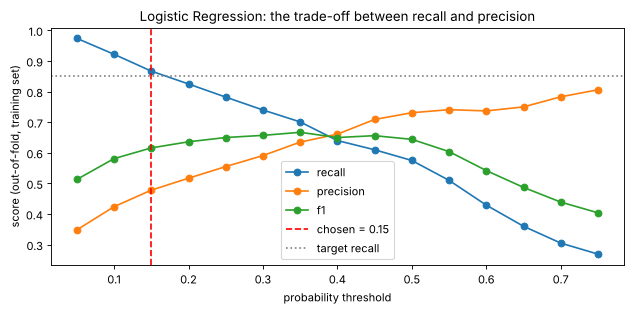

In [21]:
plt.figure(figsize=(8, 4))
for col in ["recall", "precision", "f1"]:
    plt.plot(threshold_table["threshold"], threshold_table[col], marker="o", label=col)
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"chosen = {THRESHOLD:.2f}")
plt.axhline(TARGET_RECALL, color="grey", linestyle=":", label="target recall")
plt.xlabel("probability threshold"); plt.ylabel("score (out-of-fold, training set)")
plt.title(f"{best_name}: the trade-off between recall and precision")
plt.legend(); plt.tight_layout()

Lowering the threshold raises recall and lowers precision: more mentor meetings, fewer students missed.

## 8. Final evaluation on the test set

In [22]:
def test_scores(name, model, threshold):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"model": name, "threshold": threshold,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba),
            "share_flagged": pred.mean()}

test_rows = [test_scores(n, m, 0.5) for n, m in fitted.items()]
test_rows.append(test_scores(best_name + " (chosen threshold)", best_model, THRESHOLD))
test_results = pd.DataFrame(test_rows).set_index("model").round(3)
test_results

,threshold,accuracy,precision,recall,f1,roc_auc,share_flagged
model,,,,,,,
Baseline (most frequent),0.50,0.808,0.000,0.000,0.000,0.500,0.000
Logistic Regression,0.50,0.862,0.677,0.545,0.604,0.906,0.155
Random Forest (balanced),0.50,0.835,0.551,0.766,0.641,0.900,0.268
Logistic Regression (chosen threshold),0.15,0.782,0.464,0.844,0.599,0.906,0.350


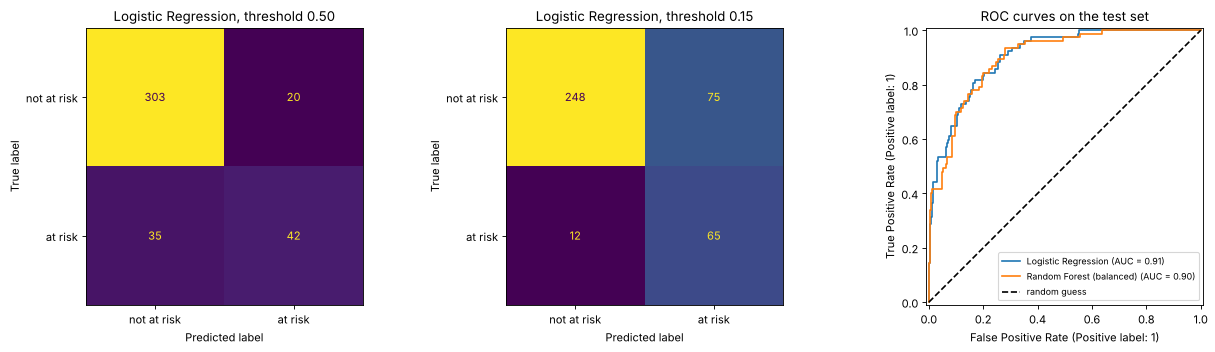

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
test_proba = best_model.predict_proba(X_test)[:, 1]
for ax, t in zip(axes[:2], [0.5, THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(y_test, (test_proba >= t).astype(int), ax=ax, colorbar=False,
                                            display_labels=["not at risk", "at risk"])
    ax.set_title(f"{best_name}, threshold {t:.2f}")
for name in ["Logistic Regression", "Random Forest (balanced)"]:
    RocCurveDisplay.from_estimator(fitted[name], X_test, y_test, ax=axes[2], name=name)
axes[2].plot([0, 1], [0, 1], "k--", label="random guess"); axes[2].legend(fontsize=8)
axes[2].set_title("ROC curves on the test set")
plt.tight_layout()

In [24]:
tn, fp, fn, tp = confusion_matrix(y_test, (test_proba >= THRESHOLD).astype(int)).ravel()
print(f"With threshold {THRESHOLD:.2f} on {len(y_test)} test students:")
print(f"  at-risk students caught (TP):        {tp}")
print(f"  at-risk students missed (FN):        {fn}")
print(f"  extra mentor check-ins (FP):         {fp}")
print(f"  correctly left alone (TN):           {tn}")
print(f"  mentor meetings needed: {tp + fp} (= {(tp + fp) / len(y_test):.0%} of students)")

With threshold 0.15 on 400 test students:
  at-risk students caught (TP):        65
  at-risk students missed (FN):        12
  extra mentor check-ins (FP):         75
  correctly left alone (TN):           248
  mentor meetings needed: 140 (= 35% of students)


**Reading the results:** compare the two confusion matrices. Moving from 0.5 to the chosen threshold catches clearly
more at-risk students (fewer false negatives) at the price of more check-ins with students who would have passed.
For a mentoring programme this is a good trade. The ROC curves of the two models are close, so the choice between them
matters less than the threshold. Exact numbers are in the tables above and in `models/model_info.json`.

## 9. Understand the model

### 9.1 Logistic regression coefficients

Because numeric inputs are standardised, each coefficient shows the effect of **one standard deviation** more of that
column on the *log-odds* of being at risk. `exp(coefficient)` is the **odds ratio**: above 1 = raises the risk,
below 1 = lowers it. For categories the effect is relative to the other categories of the same column.

In [25]:
lr = fitted["Logistic Regression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"feature": [n.split("__", 1)[1] for n in names],
                      "coefficient": lr.named_steps["model"].coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coefficient"])
coefs = coefs.reindex(coefs["coefficient"].abs().sort_values(ascending=False).index).round(3)
coefs

,feature,coefficient,odds_ratio
2,previous_sem_gpa,-1.092,0.336
4,internal_test_score,-0.853,0.426
1,attendance_pct,-0.550,0.577
10,family_support_Low,0.539,1.714
0,study_hours_per_week,-0.494,0.610
12,internet_access_No,0.336,1.399
13,internet_access_Yes,-0.334,0.716
9,family_support_High,-0.293,0.746
5,commute_minutes,0.248,1.281
11,family_support_Medium,-0.243,0.784


**Reading the coefficients:** the largest effects are previous GPA and the internal test score (both strongly
*lower* the risk, odds ratios well below 1), followed by attendance, low family support (raises the risk) and study
hours. A longer commute raises the risk a little; more sleep lowers it a little. The signs match common sense — an
important sanity check before trusting any model.

Notice that `part_time_job` gets a coefficient of almost **zero**, even though the chi-square test said it matters.
That is not a contradiction: students with a job study and attend less, and the model already sees those columns. The
job's effect works *through* them. Coefficients show the effect of one column **while the others are held fixed**.

### 9.2 Permutation importance of the chosen model

Shuffle one column at a time on the test set and measure how much ROC-AUC drops. This works for any model.
The API uses this ranking to decide which reasons to show first.

previous_sem_gpa             0.0905
internal_test_score          0.0562
study_hours_per_week         0.0233
attendance_pct               0.0147
internet_access              0.0061
family_support               0.0056
commute_minutes              0.0039
extracurricular              0.0038
sleep_hours                  0.0036
assignments_submitted_pct    0.0013
part_time_job                0.0000
dtype: float64


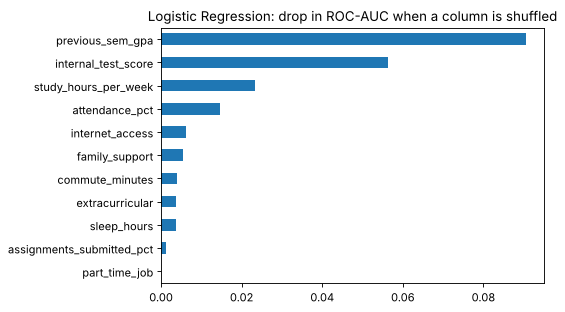

In [26]:
imp = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="roc_auc")
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
importance.plot.barh(figsize=(7, 4), title=f"{best_name}: drop in ROC-AUC when a column is shuffled")
plt.tight_layout()
print(importance.sort_values(ascending=False).round(4))

## 10. Error analysis: who do we miss?

In [27]:
analysis = X_test.copy()
analysis["actual"] = y_test.values
analysis["proba"] = test_proba
analysis["flagged"] = (test_proba >= THRESHOLD).astype(int)
caught = analysis[(analysis.actual == 1) & (analysis.flagged == 1)]
missed = analysis[(analysis.actual == 1) & (analysis.flagged == 0)]
print(f"Caught: {len(caught)}  Missed: {len(missed)}")
pd.DataFrame({"caught (median)": caught[NUMERIC].median(), "missed (median)": missed[NUMERIC].median(),
              "all students (median)": X_train[NUMERIC].median()}).round(1)

Caught: 65  Missed: 12


,caught (median),missed (median),all students (median)
study_hours_per_week,4.9,8.2,11.4
attendance_pct,71.4,79.6,79.2
previous_sem_gpa,5.0,6.4,6.7
assignments_submitted_pct,69.0,82.0,81.0
internal_test_score,20.0,26.0,27.0
commute_minutes,31.0,23.0,26.0
sleep_hours,6.6,7.2,6.9


**Reading the table:** the at-risk students the model misses look much more like ordinary students on paper — better
internal test scores and GPA than the ones it catches. Their failure is driven by things the data does not capture
(illness, personal problems, a bad exam day). **No model replaces talking to students**; teachers should still be able
to refer someone the model did not flag.

## 11. Fairness check by gender

Gender was not given to the model, but other columns could still act as a proxy. We compare, on the test set, how
often each group is flagged and how many truly at-risk students are caught in each group.

In [28]:
fair_rows = []
for g in sorted(gender_test.unique()):
    m = (gender_test == g).values
    pred_g = (test_proba[m] >= THRESHOLD).astype(int)
    fair_rows.append({"gender": g, "students": int(m.sum()),
                      "actual at-risk rate": y_test[m].mean(),
                      "flagged rate": pred_g.mean(),
                      "recall": recall_score(y_test[m], pred_g),
                      "precision": precision_score(y_test[m], pred_g, zero_division=0)})
fairness = pd.DataFrame(fair_rows).set_index("gender").round(3)
fairness

,students,actual at-risk rate,flagged rate,recall,precision
gender,,,,,
Female,180,0.206,0.367,0.892,0.500
Male,220,0.182,0.336,0.800,0.432


**In plain words:** female and male students have similar real at-risk rates, and the model flags a similar share of
each group (both roughly a third). Recall is somewhat higher for female students (about 0.89) than for male students
(about 0.80). Each group has only about 40 truly at-risk students in the test set, so one missed student moves recall by
2–3 points — the gap amounts to a handful of students and may be chance, but it is exactly the kind of gap a college
should **keep monitoring** on new terms. On real data this check must be repeated (also for other groups, such as
students with no internet access), and any lasting gap investigated before and while the tool is used.

## 12. New examples and edge cases

The API gives **reasons** in plain words. A simple, transparent approach: go through the features from most to least
important (section 9.2) and report the ones where the student is on the "risky side" of a typical student (the training
median). For numbers the risky side comes from the direction of the relationship (e.g. *low* attendance, *long*
commute); for categories it is a group whose at-risk rate is clearly above average. This is a rule of thumb, not an
exact explanation of the model.

In [29]:
FEATURE_LABELS = {
    "study_hours_per_week": "Study hours per week", "attendance_pct": "Attendance (%)",
    "previous_sem_gpa": "Previous semester GPA", "assignments_submitted_pct": "Assignments submitted (%)",
    "internal_test_score": "Internal test score (out of 50)", "commute_minutes": "Commute (minutes)",
    "sleep_hours": "Sleep per night (hours)", "part_time_job": "Part-time job",
    "family_support": "Family support", "internet_access": "Internet access at home",
    "extracurricular": "Extracurricular activities",
}
# Direction: is a LOW or a HIGH value linked with risk? (Spearman correlation on the training set)
risky_side = {c: ("low" if stats.spearmanr(X_train[c], y_train, nan_policy="omit")[0] < 0 else "high")
              for c in NUMERIC}
quartiles = {c: [float(X_train[c].quantile(q)) for q in (0.25, 0.5, 0.75)] for c in NUMERIC}
train_rate = float(y_train.mean())
category_risk = {c: y_train.groupby(X_train[c]).mean().round(3).to_dict() for c in CATEGORICAL}
importance_order = importance.sort_values(ascending=False).index.tolist()
print("Risky side:", risky_side)
print("Category at-risk rates:", category_risk)


def explain(student, max_reasons=3):
    reasons = []
    for col in importance_order:
        value = student.get(col)
        if value is None or (isinstance(value, float) and np.isnan(value)):
            continue
        if col in NUMERIC:
            q25, med, q75 = quartiles[col]
            low_risky = risky_side[col] == "low"
            # only mention a value if it is at least halfway from the median to the quartile on the risky side
            if low_risky:
                noticeable, strong = value <= (med + q25) / 2, value <= q25
            else:
                noticeable, strong = value >= (med + q75) / 2, value >= q75
            if noticeable:
                word = ("much " if strong else "") + ("lower" if low_risky else "higher")
                reasons.append(f"{FEATURE_LABELS[col]} is {value:g}, {word} than a typical student "
                               f"({round(med, 1):g}).")
        else:
            rate = category_risk[col].get(value, train_rate)
            if rate > train_rate * 1.2:
                reasons.append(f"{FEATURE_LABELS[col]}: {value}. Students in this group were at risk more often "
                               f"({rate:.0%} vs {train_rate:.0%} overall).")
        if len(reasons) == max_reasons:
            break
    return reasons

Risky side: {'study_hours_per_week': 'low', 'attendance_pct': 'low', 'previous_sem_gpa': 'low', 'assignments_submitted_pct': 'low', 'internal_test_score': 'low', 'commute_minutes': 'high', 'sleep_hours': 'low'}
Category at-risk rates: {'part_time_job': {'No': 0.177, 'Yes': 0.235}, 'family_support': {'High': 0.169, 'Low': 0.246, 'Medium': 0.179}, 'internet_access': {'No': 0.229, 'Yes': 0.184}, 'extracurricular': {'No': 0.195, 'Yes': 0.189}}


In [30]:
typical = {"study_hours_per_week": 12, "attendance_pct": 80, "previous_sem_gpa": 6.6, "assignments_submitted_pct": 80,
           "internal_test_score": 27, "commute_minutes": 25, "sleep_hours": 7, "part_time_job": "No",
           "family_support": "Medium", "internet_access": "Yes", "extracurricular": "No"}
new_students = pd.DataFrame([
    {**typical, "study_hours_per_week": 22, "attendance_pct": 95, "previous_sem_gpa": 8.5,
     "internal_test_score": 38, "assignments_submitted_pct": 100},                                   # strong student
    typical,                                                                                       # typical student
    {**typical, "study_hours_per_week": 4, "attendance_pct": 58, "previous_sem_gpa": 5.0, "internal_test_score": 17,
     "assignments_submitted_pct": 55, "part_time_job": "Yes", "commute_minutes": 75, "family_support": "Low"},  # struggling
    {**typical, "attendance_pct": np.nan, "sleep_hours": np.nan, "internal_test_score": 20},       # missing values
], index=["strong", "typical", "struggling", "missing values"])

proba = best_model.predict_proba(new_students)[:, 1]
for (label, row), p in zip(new_students.iterrows(), proba):
    print(f"{label:15s} probability {p:.2f}  at_risk={p >= THRESHOLD}")
    for r in explain(row.to_dict()):
        print("     -", r)

strong          probability 0.00  at_risk=False
typical         probability 0.04  at_risk=False
struggling      probability 0.95  at_risk=True
     - Previous semester GPA is 5, much lower than a typical student (6.7).
     - Internal test score (out of 50) is 17, much lower than a typical student (27).
     - Study hours per week is 4, much lower than a typical student (11.4).
missing values  probability 0.11  at_risk=False
     - Internal test score (out of 50) is 20, much lower than a typical student (27).


The strong and the typical student get low probabilities, below the threshold. No reasons are listed for them because none of their values is clearly on
the risky side of a typical student, while the
struggling student gets a very high one with three clear reasons. The row with missing attendance and sleep still gets
a prediction because the pipeline fills them with training medians — the API instead **requires** every field, so
that a mentor never sees a result built on guesses.

## 13. Save the pipeline and the information the API needs

We save the **whole pipeline** (preprocessing + model). `model_info.json` stores the **chosen threshold**, risk-level
cut-offs, allowed values and ranges for validation, and the medians / directions / importance order used for reasons.

In [31]:
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/student_risk_model.joblib")

chosen = test_results.loc[best_name + " (chosen threshold)"]
model_info = {
    "model_name": best_name,
    "target": "at_risk (final_score < 40)",
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "feature_labels": FEATURE_LABELS,
    "categories": {c: sorted(X_train[c].dropna().unique().tolist()) for c in CATEGORICAL},
    "numeric_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in NUMERIC},
    "threshold": THRESHOLD,
    "target_recall": TARGET_RECALL,
    "risk_levels": {"medium_from": THRESHOLD, "high_from": round(max(0.5, THRESHOLD + 0.2), 2)},
    "quartiles": quartiles,
    "risky_side": risky_side,
    "category_risk_rate": category_risk,
    "train_at_risk_rate": round(train_rate, 3),
    "importance_order": importance_order,
    "test_metrics": {k: round(float(chosen[k]), 3) for k in
                     ["accuracy", "precision", "recall", "f1", "roc_auc", "share_flagged"]},
    "fairness_by_gender": fairness.reset_index().to_dict(orient="records"),
    "train_rows": int(len(X_train)),
}
with open("models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)
print("threshold:", model_info["threshold"], " risk levels:", model_info["risk_levels"])
print(json.dumps(model_info["test_metrics"], indent=2))
print(sorted(os.listdir("models")))

threshold: 0.15  risk levels: {'medium_from': 0.15, 'high_from': 0.5}
{
  "accuracy": 0.782,
  "precision": 0.464,
  "recall": 0.844,
  "f1": 0.599,
  "roc_auc": 0.906,
  "share_flagged": 0.35
}
['model_info.json', 'student_risk_model.joblib']


In [32]:
# Reload from disk exactly as the API will, and check probabilities match
reloaded = joblib.load("models/student_risk_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test.head(5)), best_model.predict_proba(X_test.head(5)))
print("Reloaded model gives identical probabilities.")

Reloaded model gives identical probabilities.


## 14. Limitations and ethical use

- **Support, not punishment.** A flag means "offer help", never "lower expectations", "remove from a course" or "tell
  other teachers this student is weak". Students should know the programme exists and why they were contacted.
- **Not destiny.** About one in five predictions about a single student will be wrong in some way; a probability is
  a reason for a conversation, not a verdict. Mentors and teachers must be able to override it.
- **Missed students.** The model misses some struggling students (section 10). Keep other ways to ask for help open.
- **Synthetic data.** Patterns were invented to be realistic. A real college must retrain on its own records, re-check
  the threshold, and repeat the fairness check for every relevant group.
- **Sensitive columns.** Family support and part-time job describe a student's circumstances, not their effort. Use
  them to direct resources (e.g. a laptop loan for no internet access), not to judge.
- **Privacy.** Student records are personal data: restrict access to mentors and store as little as possible.
- **Simple reasons.** The reasons compare a student with a typical student; they are a helpful guide, not a precise
  explanation of the model.
- **Improvements to try:** tune the random forest with `GridSearchCV`, try gradient boosting, calibrate probabilities
  (`CalibratedClassifierCV`), use SHAP values for per-student explanations, and retrain each term.

**Next step:** start the Flask API in `backend/` (see the project README). It loads the two files saved above.